In [27]:
import json
import os
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Run notebook from analysis/ or set explicitly; path relative to cwd
RESULTS_DIR = (Path("..") / "results").resolve()

# Map full model paths to simplified names (like configs: dinov2_14, clip_16, etc.)
def simplify_model_name(full_name):
    """Convert e.g. facebook/dinov2-base -> dinov2_14, openai/clip-vit-base-patch32 -> clip_32"""
    m = full_name.lower()
    if "dinov2" in m or "dinov2-base" in m:
        return "DINOv2"
    if "dino-vitb" in m:
        return "DINO"
    if "vit-mae" in m or "mae" in m:
        return "MAE"
    if "imagenet" in m or "vit-base-patch" in m:
        if "patch32" in m or "patch 32" in m:
            return "Imagenet 32"
        return "Imagenet 16"
    if "clip" in m:
        if "patch32" in m or "patch 32" in m:
            return "CLIP 32"
        return "CLIP 16"
    return full_name.replace("/", "_")


def load_gestalt_results(results_dir=None):
    """
    Load all gestalt_eval.json files from the results directory.
    Returns: dict[model_name, dict[layer, results_dict]]
    """
    results_dir = Path(results_dir or RESULTS_DIR)
    data = defaultdict(dict)
    
    for org_dir in Path(results_dir).iterdir():
        if not org_dir.is_dir():
            continue
        for model_dir in org_dir.iterdir():
            if not model_dir.is_dir():
                continue
            model_name = f"{org_dir.name}/{model_dir.name}"
            for layer_dir in model_dir.iterdir():
                if not layer_dir.is_dir():
                    continue
                try:
                    layer = int(layer_dir.name)
                except ValueError:
                    continue
                json_path = layer_dir / "gestalt_eval.json"
                if json_path.exists():
                    with open(json_path, "r") as f:
                        data[model_name][layer] = json.load(f)
    
    return dict(data)


def plot_per_layer_accuracy(data=None, results_dir=None, models=None, subplots_per_model=True, ax=None):
    """
    Plot per-layer test accuracy for each model, compared to orientation and location accuracies.
    
    For each model: x=layer, y=accuracy; lines for base (test), orientation, location.
    subplots_per_model: if True, one subplot per model; else all models on one plot.
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}
    
    model_list = sorted(data.items())
    n = len(model_list)
    
    if subplots_per_model and n > 1:
        ncols = min(n, 3)
        nrows = (n + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
        axes = axes.flatten()
        for idx in range(n, len(axes)):
            axes[idx].set_visible(False)
    else:
        if ax is not None:
            fig = ax.figure
            axes = [ax]
        else:
            fig, ax = plt.subplots(figsize=(10, 6))
            axes = [ax]
    
    for idx, (model_name, layer_results) in enumerate(model_list):
        a = axes[idx] if subplots_per_model and n > 1 else axes[0]
        layers = sorted(layer_results.keys())
        base_acc = [layer_results[l]["standard"]["base"]["accuracy"] for l in layers]
        orient_acc = [layer_results[l]["standard"]["orientation"]["accuracy"] for l in layers]
        loc_acc = [layer_results[l]["standard"]["location"]["accuracy"] for l in layers]
        
        suff = f" ({model_name})" if not (subplots_per_model and n > 1) else ""
        a.plot(layers, base_acc, "o-", label=f"Test/base{suff}", linewidth=2, markersize=6)
        a.plot(layers, orient_acc, "s--", label=f"Orientation{suff}", alpha=0.8, markersize=4)
        a.plot(layers, loc_acc, "^-.", label=f"Location{suff}", alpha=0.8, markersize=4)
        
        a.set_xlabel("Layer")
        a.set_ylabel("Accuracy")
        if subplots_per_model and n > 1:
            a.set_title(model_name)
        else:
            a.set_title("Per-layer probe accuracy vs. orientation and location controls")
        a.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
        a.grid(True, alpha=0.3)
        a.axhline(0.5, color="gray", linestyle=":", alpha=0.5)
    
    plt.tight_layout()
    return axes[0] if len(axes) == 1 else axes


def plot_ablation_decrement_by_layer(data=None, results_dir=None, models=None, control_band="iqr", ax=None):
    """
    One subplot per model. X=layer, Y=ablation decrement.
    Control band is dynamic per (model, layer): shows distribution of control decrements at that layer.
    control_band: "std", "iqr", or "minmax"
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}

    model_list = sorted(data.items())
    n = len(model_list)
    ncols = min(n, 3)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
    axes = axes.flatten()
    for idx in range(n, len(axes)):
        axes[idx].set_visible(False)

    for idx, (model_name, layer_results) in enumerate(model_list):
        ax = axes[idx]
        short_name = simplify_model_name(model_name)
        layers = sorted(layer_results.keys())
        decs = [layer_results[l]["standard"]["base"]["accuracy"] - layer_results[l]["ablation"]["base"]["accuracy"] for l in layers]

        # Per-layer control decrements: for each layer, list of (base - c) for each control
        control_lower, control_upper = [], []
        for l in layers:
            res = layer_results[l]
            base = res["standard"]["base"]["accuracy"]
            ctrl_decs = [base - c for c in res["controls"]["base"]["accuracy"]]
            if control_band == "std":
                m, s = np.mean(ctrl_decs), np.std(ctrl_decs)
                control_lower.append(m - s)
                control_upper.append(m + s)
            elif control_band == "iqr":
                q25, q75 = np.percentile(ctrl_decs, [25, 75])
                control_lower.append(q25)
                control_upper.append(q75)
            else:
                control_lower.append(np.min(ctrl_decs))
                control_upper.append(np.max(ctrl_decs))

        ax.fill_between(layers, control_lower, control_upper, alpha=0.2, color="gray", label="Control ablations")
        ax.plot(layers, decs, "o-", color="C0", linewidth=2, markersize=6, label="Target ablation")
        ax.set_xlabel("Layer")
        ax.set_ylabel("Ablation decrement")
        ax.set_title(short_name)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color="gray", linestyle=":", alpha=0.5)

    plt.tight_layout()
    return axes


def plot_ablation_vs_baseline_gap(data=None, results_dir=None, models=None, control_band="std", ax=None):
    """
    Plot: 
      - X-axis: test_acc - max(orientation_acc, location_acc)  [gap above low-level baselines]
      - Y-axis: ablation_decrement = standard.base - ablation.base
      - Band: distribution of control ablation decrements (mean ± std or IQR)
    
    control_band: "std" for mean±std, "iqr" for 25-75th percentile, or "minmax" for full range
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}
    
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 8))
    
    # Collect points by model (simplified name)
    by_model = defaultdict(lambda: {"xs": [], "ys": []})
    control_decrements = []
    
    for model_name, layer_results in data.items():
        short_name = simplify_model_name(model_name)
        for layer, res in layer_results.items():
            base = res["standard"]["base"]["accuracy"]
            orient = res["standard"]["orientation"]["accuracy"]
            loc = res["standard"]["location"]["accuracy"]
            abl = res["ablation"]["base"]["accuracy"]
            controls = res["controls"]["base"]["accuracy"]
            
            gap = base - max(orient, loc)
            dec = base - abl
            by_model[short_name]["xs"].append(gap)
            by_model[short_name]["ys"].append(dec)
            for c in controls:
                control_decrements.append(base - c)
    
    control_decrements = np.array(control_decrements)
    
    # Plot control band (horizontal: ablation decrement on y-axis)
    if control_band == "std":
        c_mean = np.mean(control_decrements)
        c_std = np.std(control_decrements)
        ax.axhspan(c_mean - c_std, c_mean + c_std, alpha=0.2, color="gray", label=f"Control ablations (mean±1σ)")
        ax.axhline(c_mean, color="gray", linestyle="--", alpha=0.6)
    elif control_band == "iqr":
        q25, q75 = np.percentile(control_decrements, [25, 75])
        ax.axhspan(q25, q75, alpha=0.2, color="gray", label="Control ablations (IQR)")
        ax.axhline(np.median(control_decrements), color="gray", linestyle="--", alpha=0.6)
    elif control_band == "minmax":
        ax.axhspan(np.min(control_decrements), np.max(control_decrements), alpha=0.15, color="gray", label="Control ablations (min–max)")
    
    colors = plt.cm.tab10(np.linspace(0, 1, 10))
    for idx, (short_name, pts) in enumerate(sorted(by_model.items())):
        xs = np.array(pts["xs"])
        ys = np.array(pts["ys"])
        color = colors[idx % len(colors)]
        ax.scatter(xs, ys, color=color, label=short_name, alpha=0.8, s=50, edgecolors="white", linewidths=0.5)
    
    ax.set_xlabel("Test acc − max(orientation, location) acc")
    ax.set_ylabel("Ablation decrement (base − ablated)")
    ax.set_title("Probe gap over low-level baselines vs. ablation decrement\n(band = distribution of control ablation decrements)")
    ax.legend()

    # Flatten all points for correlation
    all_xs = np.concatenate([np.array(pts["xs"]) for pts in by_model.values()])
    all_ys = np.concatenate([np.array(pts["ys"]) for pts in by_model.values()])
    r, pval = stats.pearsonr(all_xs, all_ys)
    ax.text(0.05, 0.95, f"r = {r:.3f}, p = {pval:.2e}", transform=ax.transAxes, fontsize=10, verticalalignment="top",
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))

    ax.grid(True, alpha=0.3)
    ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
    ax.axvline(0, color="gray", linestyle=":", alpha=0.5)
    plt.tight_layout()
    return ax

In [28]:
# Example usage:
from typing import Any

results_path = Path("/oscar/data/epavlick/mlepori/projects/gestalt-interp/binding_probes/results")

data = load_gestalt_results(results_path)
print("Models:", list[Any](data.keys()))
print("Layers per model:", {m: sorted(d.keys()) for m, d in data.items()})

Models: ['facebook/dino-vitb16', 'facebook/dinov2-base', 'facebook/vit-mae-base', 'google/vit-base-patch16-224-in21k', 'google/vit-base-patch32-224-in21k', 'openai/clip-vit-base-patch16', 'openai/clip-vit-base-patch32']
Layers per model: {'facebook/dino-vitb16': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'facebook/dinov2-base': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'facebook/vit-mae-base': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'google/vit-base-patch16-224-in21k': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'google/vit-base-patch32-224-in21k': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'openai/clip-vit-base-patch16': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'openai/clip-vit-base-patch32': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]}


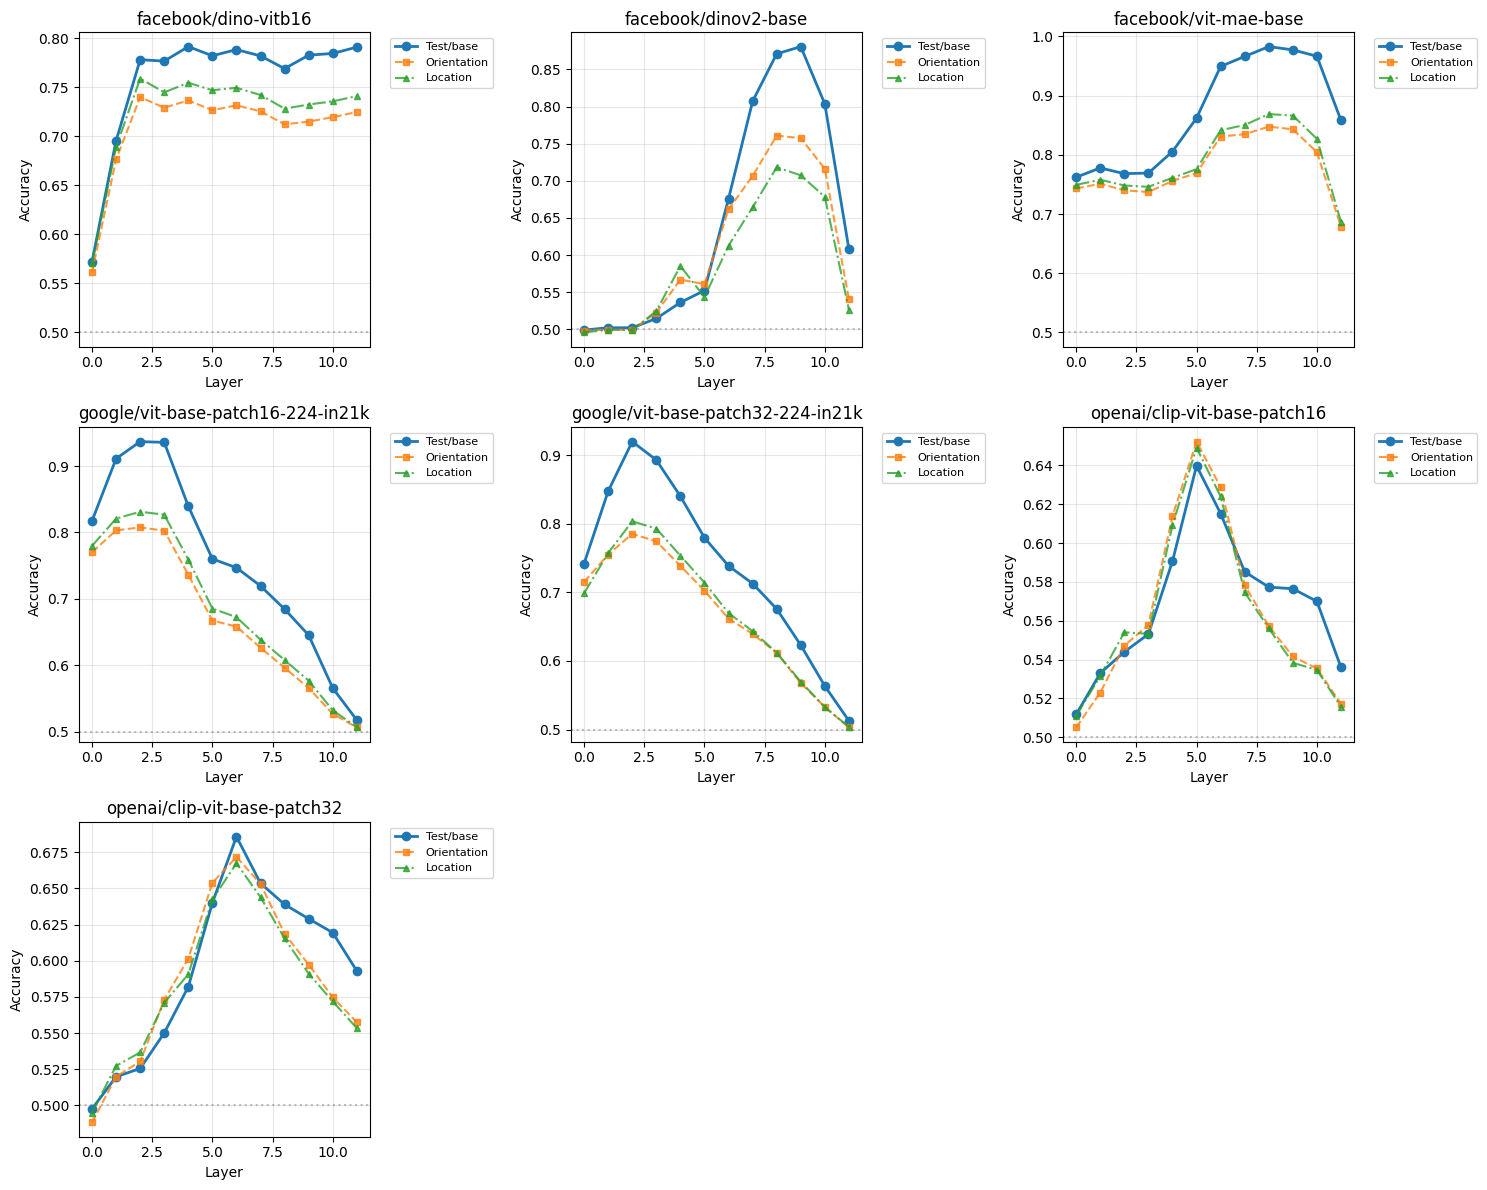

In [29]:
# Plot 1: Per-layer test accuracy vs orientation and location
plot_per_layer_accuracy(data=data)
plt.show()

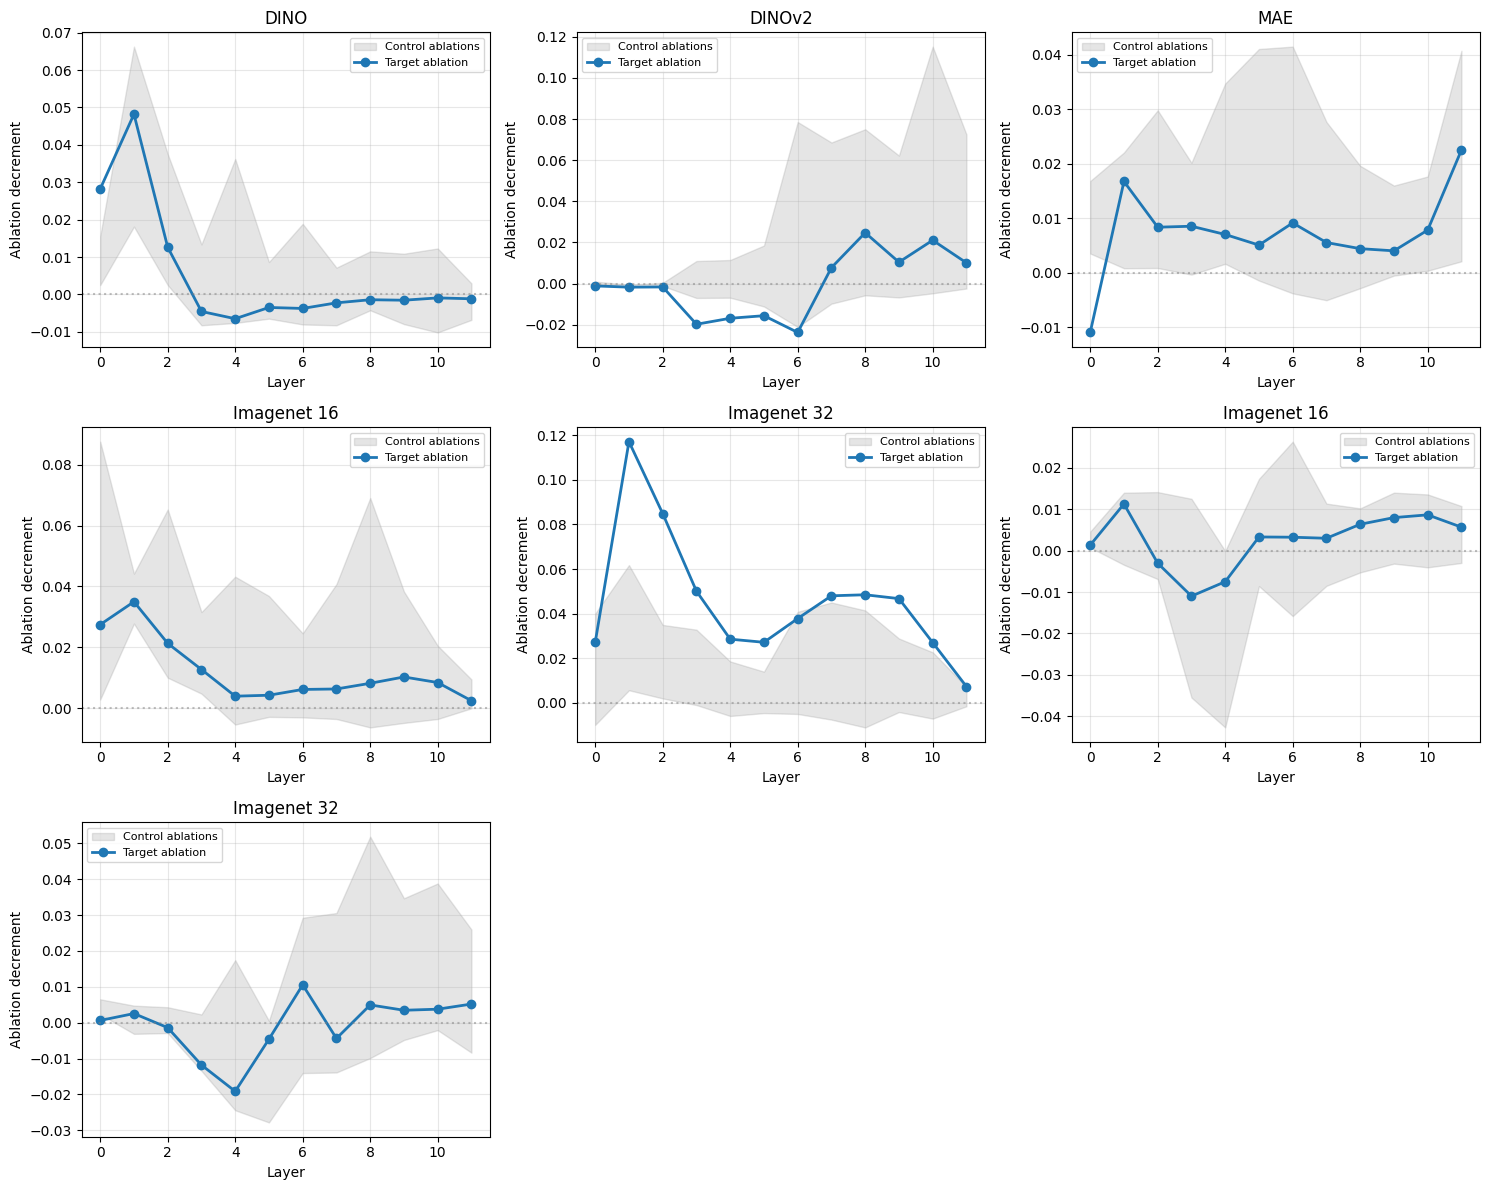

In [33]:
# Plot 2: Ablation decrement by layer (one subplot per model, dynamic control bands per layer)
plot_ablation_decrement_by_layer(data=data, control_band="minmax")
plt.show()

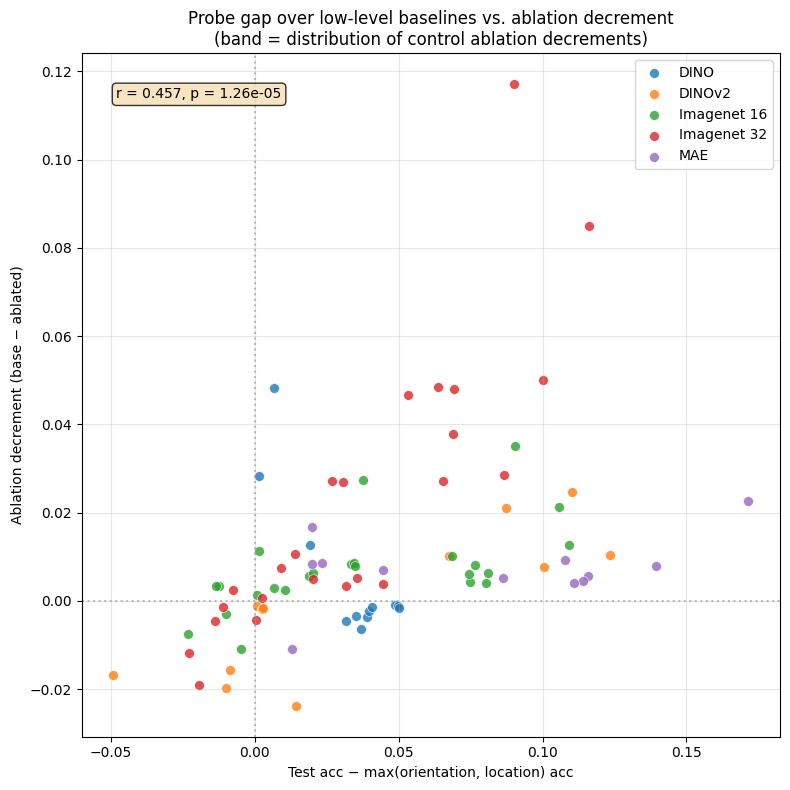

In [32]:
# Plot 2: Gap over baselines vs ablation decrement (with control band)
plot_ablation_vs_baseline_gap(data=data, control_band=None)
plt.show()